In [2]:
!pip install gensim

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

np.random.seed(42)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 62.4 MB/s  0:00:00


In [4]:
pula_zamek_budowla = [
    "Stary zamek stoi wysoko na skalistym wzgórzu.",
    "Turyści chętnie zwiedzają średniowieczny zamek królewski.",
    "Potężny zamek bronił miasta przed najazdem wrogów.",
    "Kamienny zamek otacza głęboka fosa oraz wysokie mury.",
    "Król przez lata rozbudowywał swój warowny zamek.",
    "Z wieży obserwacyjnej widać cały zamek oraz okoliczny las.",
    "Ten zabytkowy zamek przyciąga latem wielu zwiedzających.",
    "Rycerze strzegli bramy prowadzącej prosto na zamek.",
    "Wysoka wieża góruje nad całym kamiennym zamkiem.",
]

In [5]:
pula_zamek_budowla = [
    "Stary zamek stoi wysoko na skalistym wzgórzu.",
    "Turyści chętnie zwiedzają średniowieczny zamek królewski.",
    "Potężny zamek bronił miasta przed najazdem wrogów.",
    "Kamienny zamek otacza głęboka fosa oraz wysokie mury.",
    "Król przez lata rozbudowywał swój warowny zamek.",
    "Z wieży obserwacyjnej widać cały zamek oraz okoliczny las.",
    "Ten zabytkowy zamek przyciąga latem wielu zwiedzających.",
    "Rycerze strzegli bramy prowadzącej prosto na zamek.",
    "Przewodnik opowiadał zwiedzającym długą historię jak powstał zamek.",
    "Obronny zamek przetrwał liczne oblężenia oraz pożary.",
    "W muzeum wewnątrz murów można poznać dawny zamek.",
    "Królewski zamek zachwyca bogatą architekturą i wysoką wieżą.",
    "Podczas wycieczki turyści fotografowali średniowieczny zamek.",
    "Dawny zamek należał do potężnego rodu rycerskiego.",
    "Grube kamienne mury chroniły zamek przed artylerią.",
    "Zimą ośnieżony zamek wygląda niezwykle malowniczo.",
    "Przewodnik oprowadził grupę turystów przez cały zamek.",
    "Król zaprosił gości na wielką ucztę na zamek.",
    "Wieczorem oświetlony zamek widać z dalekiego wzgórza.",
    "Zabytkowy zamek wpisano na listę cennych pomników historii."
]

In [6]:
pula_zamek_drzwi = [
    "Ślusarz szybko naprawił zepsuty zamek w drzwiach wejściowych.",
    "Nowy zamek otwiera się lekko jednym przekręceniem klucza.",
    "Złodziej próbował wyłamać solidny zamek w bramie.",
    "Zardzewiały zamek zaciął się rano i zablokował drzwi.",
    "Kupiliśmy bezpieczny zamek patentowy z kompletem kluczy.",
    "Klucz nie pasował ponieważ zamek był mocno uszkodzony.",
    "Solidny zamek chroni mieszkanie przed włamaniem.",
    "Musiałem wymienić stary zamek na nowoczesny model.",
    "Ślusarz dokładnie nasmarował zacinający się zamek.",
    "Ten metalowy zamek ma bardzo skomplikowany mechanizm.",
    "Ktoś przekręcił klucz i zamknął zamek od środka.",
    "Awaryjny zamek wymagał natychmiastowej interwencji ślusarza.",
    "Zgubiony klucz zmusił nas aby rozwiercić zamek.",
    "W drzwiach zamontowano dodatkowy zamek zabezpieczający.",
    "Dobry klucz bez problemu otwiera każdy sprawny zamek.",
    "Mechanizm wewnątrz obudowy zablokował cały zamek.",
    "Ślusarz wymienił wkładkę oraz cały zamek w furtce.",
    "Po zatrzaśnięciu drzwi zamek pozostał zamknięty na klucz.",
    "Nowoczesny zamek elektroniczny zastąpił tradycyjny klucz.",
    "Zepsuty zamek utrudniał zamknięcie ciężkich drzwi."
]

In [7]:
pula_neutralna = [
    "Prognoza pogody zapowiada słoneczny i ciepły weekend.",
    "Poranna kawa pomaga szybko rozpocząć pracowity dzień.",
    "W miejskiej bibliotece można wypożyczyć ciekawe książki.",
    "Pociąg pospieszny przyjechał na peron punktualnie.",
    "Świeże warzywa i owoce są podstawą zdrowej diety.",
    "Studenci pilnie przygotowują się do nadchodzącej sesji.",
    "W parku jesienią spadają kolorowe liście z drzew.",
    "Nowy film w kinie zebrał bardzo dobre recenzje.",
    "Rowerzyści chętnie korzystają ze ścieżek wzdłuż rzeki.",
    "Wieczorny spacer poprawia samopoczucie po całym dniu.",
    "Komputer wymaga regularnej aktualizacji systemu operacyjnego.",
    "Na rynku pojawiły się lokalne produkty ekologiczne.",
    "Muzyka klasyczna sprzyja skupieniu podczas nauki.",
    "Samochód przeszedł pomyślnie coroczny przegląd techniczny.",
    "W ogrodzie zakwitły pierwsze wiosenne kwiaty.",
    "Kucharz przygotował aromatyczną zupę ze świeżych ziół.",
    "Młodzi programiści tworzą nowoczesne aplikacje webowe.",
    "Podróż samolotem trwa znacznie krócej niż jazda autem.",
    "W górach pogoda potrafi zmienić się w kilka minut.",
    "Czytanie artykułów naukowych rozwija wiedzę o świecie."
]

In [8]:
def przygotuj_zdania(lista_zdan):
    wynik = []
    for s in lista_zdan:
        czyste = re.sub(r'[^\w\s]', '', s.lower())
        wynik.append(czyste.split())
    return wynik

caly_korpus_raw = pula_zamek_budowla + pula_zamek_drzwi + pula_neutralna
caly_korpus_zdania = przygotuj_zdania(caly_korpus_raw)
caly_korpus_teksty = [" ".join(z) for z in caly_korpus_zdania]
slownik_korpusu = set(w for z in caly_korpus_zdania for w in z)

print(f"Liczebność pul: Budowla={len(pula_zamek_budowla)}, Drzwi={len(pula_zamek_drzwi)}, Neutralna={len(pula_neutralna)}")
print(f"Łącznie zdań w korpusie: {len(caly_korpus_raw)}, unikalnych słów: {len(slownik_korpusu)}\n")

pary_bpe = [
    ("zamek", "zamkami"),
    ("król", "królowi"),
    ("turyści", "turystom"),
    ("klucz", "kluczami"),
    ("drzwi", "drzwiami"),
    ("ślusarz", "ślusarzowi"),
]

formy_widziane = [p[0].lower() for p in pary_bpe]
formy_niewidziane = [p[1].lower() for p in pary_bpe]

assert all(w in slownik_korpusu for w in formy_widziane), "Błąd: któraś z form widzianych nie jest w korpusie!"
assert all(w not in slownik_korpusu for w in formy_niewidziane), "Błąd: któraś z form niewidzianych jest w korpusie!"
print("Weryfikacja par BPE zakończona pomyślnie (wszystkie formy widziane w korpusie, żadnej niewidzianej).\n")

Liczebność pul: Budowla=20, Drzwi=20, Neutralna=20
Łącznie zdań w korpusie: 60, unikalnych słów: 311

Weryfikacja par BPE zakończona pomyślnie (wszystkie formy widziane w korpusie, żadnej niewidzianej).



In [9]:
limity_vocab = [60, 150, 350]
tokenizery = {}
wyniki_bpe_tabela = []

for limit in limity_vocab:
    tok = Tokenizer(models.BPE(unk_token='[UNK]'))
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(vocab_size=limit, special_tokens=['[UNK]'], min_frequency=1)
    tok.train_from_iterator(caly_korpus_teksty, trainer)
    tokenizery[limit] = tok

    tok_widziane = [tok.encode(w).tokens for w in formy_widziane]
    tok_niewidziane = [tok.encode(w).tokens for w in formy_niewidziane]

    sr_widziane = np.mean([len(t) for t in tok_widziane])
    unk_widziane = sum(1 for t in tok_widziane if '[UNK]' in t)

    sr_niewidziane = np.mean([len(t) for t in tok_niewidziane])
    unk_niewidziane = sum(1 for t in tok_niewidziane if '[UNK]' in t)

    wyniki_bpe_tabela.append({
        "Limit vocab_size": limit,
        "Faktyczny rozmiar słownika": tok.get_vocab_size(),
        "Śr. tokenów (widziane)": round(sr_widziane, 2),
        "Liczba [UNK] (widziane)": unk_widziane,
        "Śr. tokenów (niewidziane)": round(sr_niewidziane, 2),
        "Liczba [UNK] (niewidziane)": unk_niewidziane,
    })

df_bpe = pd.DataFrame(wyniki_bpe_tabela)
print("=== WYNIKI BPE (TABELA) ===")
print(df_bpe.to_string(index=False))
print()

wybrane_niewidziane = ["zamkami", "ślusarzowi"]
print("=== PODZIAŁY WYBRANYCH NIEWIDZIANYCH FORM ===")
for slowo in wybrane_niewidziane:
    print(f"Słowo: '{slowo}'")
    for limit in limity_vocab:
        print(f"  vocab_size={limit:3d} -> {tokenizery[limit].encode(slowo).tokens}")
print()

=== WYNIKI BPE (TABELA) ===
 Limit vocab_size  Faktyczny rozmiar słownika  Śr. tokenów (widziane)  Liczba [UNK] (widziane)  Śr. tokenów (niewidziane)  Liczba [UNK] (niewidziane)
               60                          60                    3.67                        0                       5.83                           0
              150                         150                    1.83                        0                       4.17                           0
              350                         350                    1.00                        0                       3.50                           0

=== PODZIAŁY WYBRANYCH NIEWIDZIANYCH FORM ===
Słowo: 'zamkami'
  vocab_size= 60 -> ['zam', 'ka', 'm', 'i']
  vocab_size=150 -> ['zam', 'ka', 'm', 'i']
  vocab_size=350 -> ['zam', 'ka', 'm', 'i']
Słowo: 'ślusarzowi'
  vocab_size= 60 -> ['ś', 'lu', 's', 'a', 'rz', 'ow', 'i']
  vocab_size=150 -> ['ślu', 'sa', 'rz', 'ow', 'i']
  vocab_size=350 -> ['ślusarz', 'ow', 'i']



In [10]:
MNOZNIK = 15

wariant_1_raw = (pula_zamek_budowla[:16] + pula_zamek_drzwi[:4] + pula_neutralna) * MNOZNIK
wariant_2_raw = (pula_zamek_budowla[:4] + pula_zamek_drzwi[:16] + pula_neutralna) * MNOZNIK

zdania_w1 = przygotuj_zdania(wariant_1_raw)
zdania_w2 = przygotuj_zdania(wariant_2_raw)

w2v_params = dict(vector_size=50, window=4, min_count=5, sg=1, epochs=150, seed=42, workers=1)

model_w1 = Word2Vec(zdania_w1, **w2v_params)
model_w2 = Word2Vec(zdania_w2, **w2v_params)

sasiedzi_w1 = model_w1.wv.most_similar("zamek", topn=5)
sasiedzi_w2 = model_w2.wv.most_similar("zamek", topn=5)

df_w2v = pd.DataFrame({
    "Pozycja": range(1, 6),
    "Wariant 1 (Budowla) - Słowo": [s[0] for s in sasiedzi_w1],
    "Wariant 1 - Cosinus": [round(s[1], 4) for s in sasiedzi_w1],
    "Wariant 2 (Drzwi) - Słowo": [s[0] for s in sasiedzi_w2],
    "Wariant 2 - Cosinus": [round(s[1], 4) for s in sasiedzi_w2],
})

print("5 NAJBLIŻSZYCH SĄSIADÓW SŁOWA 'zamek' W WORD2VEC ")
print(df_w2v.to_string(index=False))
print()

top5_w2_slowa = set(s[0] for s in sasiedzi_w2)
print(" WERYFIKACJA SŁÓW Z TOP 5 WARIANTU 1 W MODELU 2 ")
for slowo, _ in sasiedzi_w1:
    if slowo not in top5_w2_slowa:
        czy_jest = slowo in model_w2.wv
        sim_w2 = round(float(model_w2.wv.similarity("zamek", slowo)), 4) if czy_jest else None
        print(f"  Słowo '{slowo}' wypadło z TOP 5 -> w słowniku modelu 2: {czy_jest}, podobieństwo do 'zamek': {sim_w2}")
print()

5 NAJBLIŻSZYCH SĄSIADÓW SŁOWA 'zamek' W WORD2VEC 
 Pozycja Wariant 1 (Budowla) - Słowo  Wariant 1 - Cosinus Wariant 2 (Drzwi) - Słowo  Wariant 2 - Cosinus
       1                        mury               0.3949                   ślusarz               0.4516
       2                        oraz               0.3890                     klucz               0.4238
       3                         las               0.3654                     przed               0.3877
       4                     turyści               0.3642                 mechanizm               0.3813
       5                     powstał               0.3555                     stary               0.3668

 WERYFIKACJA SŁÓW Z TOP 5 WARIANTU 1 W MODELU 2 
  Słowo 'mury' wypadło z TOP 5 -> w słowniku modelu 2: True, podobieństwo do 'zamek': 0.246
  Słowo 'oraz' wypadło z TOP 5 -> w słowniku modelu 2: True, podobieństwo do 'zamek': 0.2117
  Słowo 'las' wypadło z TOP 5 -> w słowniku modelu 2: False, podobieństwo do 'zamek':

Uwaga: Następujące słowa zostały pominięte, ponieważ nie ma ich w słowniku modelu 1: ['klucz', 'mechanizm']

=== PODOBIEŃSTWO COSINUSOWE GRUP TEMATYCZNYCH (MODEL 1) ===
  Średnie podobieństwo wewnątrz Grupy 1 (Budowla): 0.4297
  Średnie podobieństwo wewnątrz Grupy 2 (Drzwi):   0.4954
  Średnie podobieństwo MIĘDZY grupami:              0.4123
  Przykład pary z jednej grupy ('średniowieczny', 'turyści'): 0.9626
  Przykład pary między grupami ('średniowieczny', 'ślusarz'): 0.4145


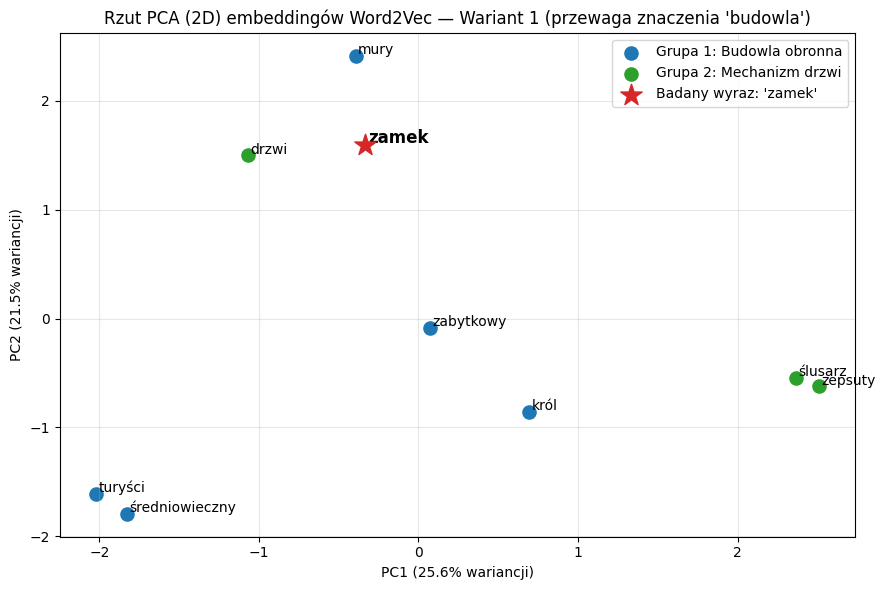

In [13]:
grupa_budowla_raw = ["średniowieczny", "król", "mury", "turyści", "zabytkowy"]
grupa_drzwi_raw = ["klucz", "ślusarz", "drzwi", "zepsuty", "mechanizm"]
badany_wyraz = ["zamek"]

grupa_budowla = [w for w in grupa_budowla_raw if w in model_w1.wv]
grupa_drzwi = [w for w in grupa_drzwi_raw if w in model_w1.wv]
pominiete = [w for w in (grupa_budowla_raw + grupa_drzwi_raw) if w not in model_w1.wv]

if pominiete:
    print(f"Uwaga: Następujące słowa zostały pominięte, ponieważ nie ma ich w słowniku modelu 1: {pominiete}\n")

def srednie_podobienstwo_wewnatrz(model, grupa):
    if len(grupa) < 2:
        return 0.0, [], []
    pary = list(combinations(grupa, 2))
    wartosci = [model.wv.similarity(w1, w2) for w1, w2 in pary]
    return float(np.mean(wartosci)), pary, wartosci

def srednie_podobienstwo_miedzy(model, g1, g2):
    if not g1 or not g2:
        return 0.0, [], []
    pary = [(w1, w2) for w1 in g1 for w2 in g2]
    wartosci = [model.wv.similarity(w1, w2) for w1, w2 in pary]
    return float(np.mean(wartosci)), pary, wartosci

sim_g1, _, _ = srednie_podobienstwo_wewnatrz(model_w1, grupa_budowla)
sim_g2, _, _ = srednie_podobienstwo_wewnatrz(model_w1, grupa_drzwi)
sim_miedzy, _, _ = srednie_podobienstwo_miedzy(model_w1, grupa_budowla, grupa_drzwi)

print("=== PODOBIEŃSTWO COSINUSOWE GRUP TEMATYCZNYCH (MODEL 1) ===")
print(f"  Średnie podobieństwo wewnątrz Grupy 1 (Budowla): {sim_g1:.4f}")
print(f"  Średnie podobieństwo wewnątrz Grupy 2 (Drzwi):   {sim_g2:.4f}")
print(f"  Średnie podobieństwo MIĘDZY grupami:              {sim_miedzy:.4f}")
if "średniowieczny" in model_w1.wv and "turyści" in model_w1.wv:
    print(f"  Przykład pary z jednej grupy ('średniowieczny', 'turyści'): {model_w1.wv.similarity('średniowieczny', 'turyści'):.4f}")
if "średniowieczny" in model_w1.wv and "ślusarz" in model_w1.wv:
    print(f"  Przykład pary między grupami ('średniowieczny', 'ślusarz'): {model_w1.wv.similarity('średniowieczny', 'ślusarz'):.4f}")

wszystkie_slowa_pca = grupa_budowla + grupa_drzwi + badany_wyraz
wektory_pca = np.stack([model_w1.wv[w] for w in wszystkie_slowa_pca])
pca = PCA(n_components=2, random_state=42)
wspolrzedne = pca.fit_transform(wektory_pca)

n1 = len(grupa_budowla)
n2 = len(grupa_drzwi)

plt.figure(figsize=(9, 6))

if n1 > 0:
    plt.scatter(wspolrzedne[:n1, 0], wspolrzedne[:n1, 1], color='#1f77b4', s=90, label='Grupa 1: Budowla obronna')
if n2 > 0:
    plt.scatter(wspolrzedne[n1:n1+n2, 0], wspolrzedne[n1:n1+n2, 1], color='#2ca02c', s=90, label='Grupa 2: Mechanizm drzwi')
plt.scatter(wspolrzedne[-1, 0], wspolrzedne[-1, 1], color='#d62728', marker='*', s=260, zorder=5, label="Badany wyraz: 'zamek'")

for (x, y), slowo in zip(wspolrzedne, wszystkie_slowa_pca):
    waga_czcionki = 'bold' if slowo == 'zamek' else 'normal'
    rozmiar_czcionki = 12 if slowo == 'zamek' else 10
    plt.annotate(slowo, (x + 0.015, y + 0.015), fontsize=rozmiar_czcionki, fontweight=waga_czcionki)

plt.title("Rzut PCA (2D) embeddingów Word2Vec — Wariant 1 (przewaga znaczenia 'budowla')")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% wariancji)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% wariancji)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()